# 🚀 Reto Exprés S12 · Equipo 5 Green
## Tema 6: Predicción de Cancelaciones de Reservas (TurisData Canarias)

**Integrantes del equipo 5 Green:** Anzhela, Cristina, Miguel, Fran y Andrii.

---
### 📌 ¿Qué vamos a hacer en este cuaderno?
1. **Cargar y limpiar** las 6.000 reservas de hoteles de TurisData Canarias.
2. **Entrenar varios modelos de IA** (redes neuronales con distintos tamaños) y compararlos contra un **rival simple** (Regresión Logística).
3. **Elegir el mejor modelo y el mejor umbral** mirando únicamente los datos de **validación**.
4. **Evaluar una sola vez en la prueba final** y calcular cuánto dinero (€) ahorramos.
5. **Probar nuestra aplicación en vivo** simulando una reserva nueva.

### ⚙️ Paso 1: Preparación del entorno y descarga de herramientas

**Explicación en lenguaje sencillo de qué hace este código:**
- Importa las librerías necesarias (como `pandas` para manejar tablas de datos, `numpy` para matemáticas, `matplotlib` para gráficos, `tensorflow/keras` para crear la red neuronal y `scikit-learn` para dividir datos y calcular métricas).
- Crea una función llamada `dato()` que descarga automáticamente el archivo `reservas_turisdata.csv` desde Internet si no lo tienes guardado en tu carpeta.
- Fija una `SEMILLA = 42` para que, cada vez que ejecutemos el código, los resultados aleatorios sean exactamente los mismos.

In [1]:
#@title ⚙️ Ejecuta esta celda primero (Preparación)
import os, re, urllib.request, time  # Herramientas básicas del sistema, internet y medición de tiempo

# Dirección web donde están guardados los datos del curso
BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

# Función para buscar o descargar el archivo de datos automáticamente
def dato(nombre):
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta): return ruta  # Si ya existe, devuelve su ubicación
    os.makedirs("datos", exist_ok=True)        # Si no existe, crea la carpeta 'datos'
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)  # Descarga el archivo desde GitHub
    return ruta

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # Oculta mensajes técnicos innecesarios de TensorFlow
import numpy as np, pandas as pd, matplotlib.pyplot as plt  # Librerías de cálculo, tablas y gráficos
SEMILLA = 42  # Número fijo para que los resultados siempre salgan igual (reproducibilidad)

from tensorflow import keras  # Librería para construir redes neuronales
keras.utils.set_random_seed(SEMILLA)  # Aplicamos la semilla a la red neuronal

# Herramientas de Scikit-Learn para dividir datos, preparar columnas y evaluar resultados
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix

print("Listo ✔ Todo preparado para empezar")

Listo ✔ Todo preparado para empezar


### ⚙️ Paso 2: Cargar y preparar las reservas

**Explicación en lenguaje sencillo de qué hace este código:**
1. **Lee el archivo CSV** de las 6.000 reservas y extrae el mes de llegada (`mes_llegada`).
2. **Quita columnas que no sirven o harían trampa:** Elimina `id_reserva` (es solo un número de fila) y las fechas exactas, separando las características (`X`) de lo que queremos adivinar (`y`, que es si se canceló o no).
3. **Divide los datos en 3 grupos:**
   - **Entrenamiento (`A_ent`):** Para que la IA estudie y aprenda patrones.
   - **Validación (`A_val`):** Para hacer pruebas y elegir el mejor modelo sin hacer trampas.
   - **Prueba (`A_pru`, 25 %):** El examen final que solo miraremos **una única vez**.
4. **Traduce texto a números:** La IA solo entiende números. Con `OneHotEncoder` convierte palabras (como el tipo de tarifa o canal) en columnas de ceros y unos, y con `StandardScaler` pone todos los números en la misma escala.

In [2]:
# 1. Leemos el archivo de reservas y convertimos las columnas de fecha a formato calendario
reservas = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])

# 2. Creamos una columna nueva con el número del mes en que llega el cliente (1 = enero, 12 = diciembre)
reservas["mes_llegada"] = reservas["fecha_llegada"].dt.month

# 3. Separamos los datos de entrada (X) y la respuesta correcta que queremos predecir (y = cancelada)
X = reservas.drop(columns=["id_reserva", "fecha_reserva", "fecha_llegada", "cancelada"])
y = reservas["cancelada"].to_numpy()

# 4. Dividimos los datos: primero guardamos un 25% para el examen final (Prueba: X_pru, y_pru)
X_res, X_pru, y_res, y_pru = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
# Del 75% restante, separamos otro 25% para Validación (X_val) y el resto para Entrenamiento (X_ent)
X_ent, X_val, y_ent, y_val = train_test_split(X_res, y_res, test_size=0.25, stratify=y_res, random_state=SEMILLA)

# 5. Identificamos qué columnas son palabras (cat) y cuáles son números (num)
cat = X.select_dtypes("object").columns.tolist()
num = [c for c in X.columns if c not in cat]

# 6. Creamos el transformador: escala los números y convierte las palabras en 0s y 1s (aprendiendo solo de X_ent)
prep = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)
]).fit(X_ent)

# Función rápida para transformar cualquier tabla en matriz numérica de 32 bits (formato ideal para redes neuronales)
f32 = lambda D: np.asarray(prep.transform(D).todense() if hasattr(prep.transform(D), "todense") else prep.transform(D), dtype="float32")
A_ent, A_val, A_pru = f32(X_ent), f32(X_val), f32(X_pru)

# Mostramos un resumen de cómo han quedado los datos
print(f"{len(reservas)} reservas · {A_ent.shape[1]} columnas tras el preparado · se cancela el {y.mean():.1%}")
print(f"LÍNEA BASE: decir «no se cancela» a todas acierta el {(1 - y_pru.mean()):.1%} (pero no detecta ninguna cancelación).")

6000 reservas · 35 columnas tras el preparado · se cancela el 45.9%
LÍNEA BASE: decir «no se cancela» a todas acierta el 54.1% (pero no detecta ninguna cancelación).


### ⚙️ Paso 3: Definir los modelos candidatos

**Explicación en lenguaje sencillo de qué hace este código:**
- Prepara nuestra **fábrica de redes neuronales** (`def entrenar`): construye una red con una capa oculta de `N` neuronas (usando activación `relu`), le añade un freno de seguridad (`Dropout(0.2)`) para que no memorice de memoria los datos, y termina con 1 neurona (`sigmoid`) que nos da la probabilidad de cancelación entre 0 y 1.
- Además, incluye `EarlyStopping`: si la red deja de mejorar durante 6 vueltas (`patience=6`), se detiene automáticamente para ahorrar tiempo y evitar errores.
- También entrena al **rival simple** (`LogisticRegression`): un modelo estadístico clásico y muy rápido al que nuestra red neuronal tendrá que superar.

In [3]:
# Función que construye y entrena una red neuronal con el número de neuronas que le pidamos
def entrenar(neuronas, epocas=60):
    keras.utils.set_random_seed(SEMILLA)  # Fijamos semilla para comparar en igualdad de condiciones
    m = keras.Sequential([
        keras.layers.Input((A_ent.shape[1],)),         # Capa de entrada: tantas puertas como columnas tenemos
        keras.layers.Dense(neuronas, activation="relu"), # Capa oculta: neuronas que buscan patrones complejos
        keras.layers.Dropout(0.2),                     # Apaga el 20% de neuronas al azar para evitar que memorice
        keras.layers.Dense(1, activation="sigmoid")    # Capa de salida: devuelve una probabilidad entre 0 y 1
    ])
    # Configuramos cómo aprende la red (optimizador Adam) y cómo mide su error (binary_crossentropy)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    # Si en 6 épocas no mejora en validación, para y quédate con la mejor versión
    parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
    # Entrenamos la red
    h = m.fit(A_ent, y_ent, validation_data=(A_val, y_val), epochs=epocas, batch_size=64, callbacks=[parar], verbose=0)
    return m, h

# Entrenamos el rival simple: Regresión Logística
simple = LogisticRegression(max_iter=1000).fit(A_ent, y_ent)
print("Listo ✔ Modelos base preparados")

Listo ✔ Modelos base preparados


### ✏️ Paso 4 (Celda 1): Probar 3 tamaños de red y elegir el mejor

**Explicación en lenguaje sencillo de qué hace este código:**
- Probamos **3 tamaños distintos** de red neuronal: `4`, `16` y `64` neuronas.
- Medimos su nota (`val_auc`) usando **solo los datos de validación** y los comparamos con el rival simple.
- **Importante:** Un AUC de `0.50` es adivinar a cara o cruz; cuanto más cerca de `1.0`, mejor distingue quién va a cancelar.
- En la última línea fijamos `ELEGIDA = 16` (porque con 16 neuronas suele conseguir un gran equilibrio sin tardar demasiado; si empatara o perdiera contra la regresión logística, pondríamos `0`).

In [4]:
PRUEBAS = [4, 16, 64]      # ✏️ Probamos 3 tamaños distintos de neuronas en la capa oculta

# Guardamos primero la nota (AUC en validación) del rival simple
filas = [dict(
    candidata="regresión logística (rival)",
    val_auc=round(float(roc_auc_score(y_val, simple.predict_proba(A_val)[:, 1])), 3),
    epocas="-",
    segundos="-"
)]

# Entrenamos cada uno de los 3 tamaños de red y guardamos su nota y tiempo
for n in PRUEBAS:
    t0 = time.time()
    m, h = entrenar(n)
    filas.append(dict(
        candidata=f"red de {n} neuronas",
        val_auc=round(float(roc_auc_score(y_val, m.predict(A_val, verbose=0).ravel())), 3),
        epocas=len(h.history["loss"]),
        segundos=round(time.time() - t0, 1)
    ))

# Mostramos la tabla comparativa ordenada
tabla = pd.DataFrame(filas)
display(tabla)

ELEGIDA = 16               # ✏️ Elegimos 16 neuronas (pon 0 si prefieres quedarte con la regresión logística)

,candidata,val_auc,epocas,segundos
0,regresión logística (rival),0.764,-,-
1,red de 4 neuronas,0.755,33,17.2
2,red de 16 neuronas,0.756,24,5.9
3,red de 64 neuronas,0.760,18,6.0


### ✏️ Paso 5 (Celda 2): Elegir el umbral según el coste en euros (€)

**Explicación en lenguaje sencillo de qué hace este código:**
- La IA nos da una probabilidad (ej. *"esta reserva tiene un 45% de riesgo de cancelarse"*). Nosotros decidimos a partir de qué porcentaje (`UMBRAL`) llamamos o enviamos una oferta al cliente.
- Definimos cuánto cuesta cada error:
  - **`COSTE_ESCAPA = 50` €:** El cliente cancela sin que le hayamos avisado y nos deja una habitación vacía.
  - **`COSTE_AVISO = 30` €:** Avisamos o damos un descuento a alguien que en realidad NO iba a cancelar.
- El código prueba muchos umbrales (del 10% al 90%) en validación y calcula cuánto dinero perderíamos en cada caso, para elegir el umbral más barato (`UMBRAL = 0.40`).

In [5]:
COSTE_ESCAPA = 50        # ✏️ € que perdemos si una cancelación se nos escapa sin avisar
COSTE_AVISO = 30         # ✏️ € que gastamos en un aviso o descuento innecesario

# Preparamos el modelo ganador que elegimos en la celda anterior
if ELEGIDA > 0:
    modelo, hist = entrenar(ELEGIDA)
    predecir = lambda A: modelo.predict(A, verbose=0).ravel()
else:
    predecir = lambda A: simple.predict_proba(A)[:, 1]

# Calculamos las probabilidades sobre los datos de validación
p_val = predecir(A_val)

# Función que suma el dinero perdido según los fallos cometidos
def coste(y, p, u):
    av = p >= u  # Decidimos avisar si la probabilidad supera o iguala el umbral 'u'
    falsas_alarmas = int((av & (y == 0)).sum()) * COSTE_AVISO   # Avisamos pero no cancelaba
    escapadas = int((~av & (y == 1)).sum()) * COSTE_ESCAPA       # No avisamos y sí canceló
    return falsas_alarmas + escapadas

# Probamos umbrales desde 0.10 (10%) hasta 0.90 (90%) de 0.05 en 0.05
umbrales = np.round(np.arange(0.1, 0.91, 0.05), 2)
costes = [coste(y_val, p_val, u) for u in umbrales]

# Mostramos una tabla con los costes de cada umbral
display(pd.DataFrame(dict(umbral=umbrales, coste_eur=costes)).iloc[::2].T)
print("Sin modelo: no avisar a nadie =", coste(y_val, p_val, 2), "€ · avisar a todos =", coste(y_val, p_val, 0), "€")

UMBRAL = 0.4             # ✏️ Elegimos 0.40 (40%) porque es donde más baja el coste en euros

,0,2,4,6,8,10,12,14,16
umbral,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
coste_eur,17180.0,15430.0,14190.0,13450.0,13630.0,15750.0,19100.0,22470.0,25360.0


Sin modelo: no avisar a nadie = 25800 € · avisar a todos = 18270 €


### ⚙️ Paso 6: El examen final (La Prueba, una sola vez)

**Explicación en lenguaje sencillo de qué hace este código:**
- Ahora sí: abrimos el sobre cerrado del 25% de reservas de **Prueba (`A_pru`)** que nunca habíamos tocado.
- Calculamos la nota final (`AUC`) tanto de nuestro modelo elegido como del rival simple para ver quién gana.
- Calculamos qué porcentaje de cancelaciones reales pillamos (`recall`), cuántas falsas alarmas damos, y cuánto dinero exacto ahorramos frente a no hacer nada.
- Imprime la **FICHA OFICIAL** que llevaremos a nuestra presentación.

In [6]:
# Calculamos predicciones y nota AUC en el conjunto de Prueba (examen final)
p_pru = predecir(A_pru)
auc_m = roc_auc_score(y_pru, p_pru)
auc_s = roc_auc_score(y_pru, simple.predict_proba(A_pru)[:, 1])

# Aplicamos el umbral elegido y construimos la matriz de confusión (aciertos y fallos en %)
av = p_pru >= UMBRAL
cm = confusion_matrix(y_pru, av, normalize="true")

# Calculamos el coste económico en la prueba
c_modelo = coste(y_pru, p_pru, UMBRAL)
c_nadie = coste(y_pru, p_pru, 2)   # Coste de no hacer nada
c_todos = coste(y_pru, p_pru, 0)   # Coste de avisar a todo el hotel

# Guardamos todos los resultados en un diccionario llamado FICHA
FICHA = dict(
    elegida=ELEGIDA, umbral=UMBRAL, auc_simple=round(auc_s, 3), auc=round(auc_m, 3),
    recall=round(float(cm[1, 1]), 3), falsas_alarmas=round(float(cm[0, 1]), 3),
    coste=c_modelo, coste_nadie=c_nadie, coste_todos=c_todos,
    ahorro=c_nadie - c_modelo, reservas=len(y_pru)
)

# Imprimimos la Ficha completa para copiarla en la presentación
print(f"""
================ FICHA PARA LA PRESENTACIÓN ================
Problema ........ predecir si la reserva se cancela · {len(reservas)} reservas
Candidatas ...... {[(f['candidata'], f['val_auc']) for f in filas]}  (AUC en validación)
Elegida ......... {"red de %d neuronas" % ELEGIDA if ELEGIDA > 0 else "regresión logística"} · umbral {UMBRAL}   (costes: escapa {COSTE_ESCAPA} €, aviso {COSTE_AVISO} €)
--- PRUEBA (una sola vez; {len(y_pru)} reservas) ---
AUC rival {auc_s:.3f} · AUC elegida {auc_m:.3f}   {"(la red gana)" if auc_m > auc_s + 0.01 else "(la red NO gana de forma clara)"}
Detecta el {cm[1, 1]:.0%} de las cancelaciones con un {cm[0, 1]:.0%} de falsas alarmas
Coste {c_modelo} € · sin modelo {c_nadie} € · avisando a todos {c_todos} €  → ahorro {c_nadie - c_modelo} €
============================================================
""")


================ FICHA PARA LA PRESENTACIÓN ================
Problema ........ predecir si la reserva se cancela · 6000 reservas
Candidatas ...... [('regresión logística (rival)', 0.764), ('red de 4 neuronas', 0.755), ('red de 16 neuronas', 0.756), ('red de 64 neuronas', 0.76)]  (AUC en validación)
Elegida ......... red de 16 neuronas · umbral 0.4   (costes: escapa 50 €, aviso 30 €)
--- PRUEBA (una sola vez; 1500 reservas) ---
AUC rival 0.741 · AUC elegida 0.735   (la red NO gana de forma clara)
Detecta el 77% de las cancelaciones con un 46% de falsas alarmas
Coste 19110 € · sin modelo 34400 € · avisando a todos 24360 €  → ahorro 15290 €



### ✏️ Paso 7 (Celda 3): Generar el titular y los gráficos para contar la historia

**Explicación en lenguaje sencillo de qué hace este código:**
- Crea automáticamente un **titular periodístico con cifras reales** (usando variables dinámicas `f-string`, sin escribir números a mano).
- Dibuja dos gráficos lado a lado:
  1. **Izquierda (Matriz de confusión):** Muestra qué porcentaje de clientes que cancelan detectamos bien y cuántas falsas alarmas damos.
  2. **Derecha (Curva de coste):** Muestra cómo baja el gasto en euros según el umbral elegido, con el eje vertical empezando estrictamente en **0 €** para no engañar visualmente.

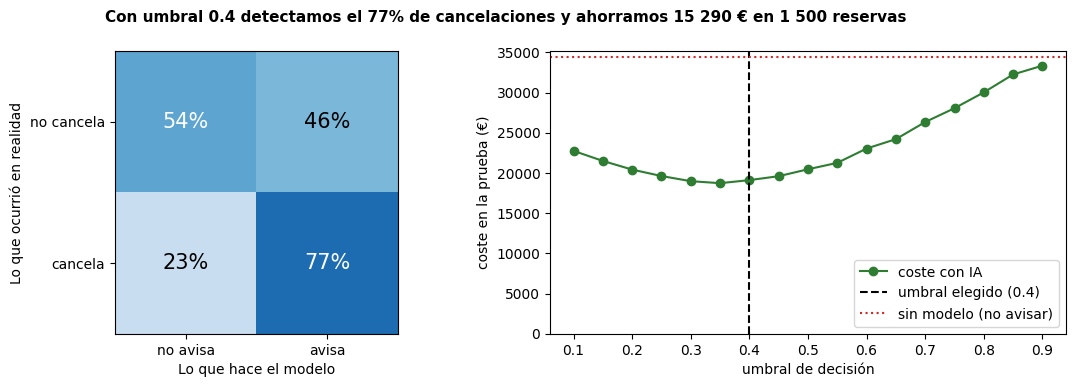

In [7]:
# ✏️ Titular automático con las cifras reales calculadas por el modelo
TITULAR = f"Con umbral {UMBRAL} detectamos el {cm[1, 1]:.0%} de cancelaciones y ahorramos {c_nadie - c_modelo:,} € en {len(y_pru):,} reservas".replace(",", " ")

# Creamos una figura con 2 gráficos juntos
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))

# Gráfico 1 (Izquierda): Matriz de confusión en porcentajes
ax[0].imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=15, color="white" if cm[i, j] > .5 else "black")
ax[0].set_xticks([0, 1], ["no avisa", "avisa"])
ax[0].set_yticks([0, 1], ["no cancela", "cancela"])
ax[0].set_xlabel("Lo que hace el modelo")
ax[0].set_ylabel("Lo que ocurrió en realidad")

# Gráfico 2 (Derecha): Evolución del coste en euros según el umbral (empezando en 0)
cp = [coste(y_pru, p_pru, x) for x in umbrales]
ax[1].plot(umbrales, cp, marker="o", color="#2E7D32", label="coste con IA")
ax[1].axvline(UMBRAL, color="black", ls="--", label=f"umbral elegido ({UMBRAL})")
ax[1].axhline(c_nadie, color="tab:red", ls=":", label="sin modelo (no avisar)")
ax[1].set_ylim(0, None)  # Obligatorio: el eje empieza en 0
ax[1].set_xlabel("umbral de decisión")
ax[1].set_ylabel("coste en la prueba (€)")
ax[1].legend()

# Ponemos el titular arriba y mostramos los gráficos
fig.suptitle(TITULAR, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

FICHA["titular"] = TITULAR

### ✏️ Paso 8 (Celda 4): La aplicación en vivo (Demo para la presentación)

**Explicación en lenguaje sencillo de qué hace este código:**
- Crea la función `probar(i, cambios...)` que sirve como simulador en vivo.
- Coge una reserva real del conjunto de prueba (por ejemplo, la reserva `0`), nos permite cambiarle datos sobre la marcha (como poner `deposito="total"`, `tarifa="no_reembolsable"` o cambiar los días de antelación) y nos dice al instante qué probabilidad tiene de cancelarse y si debemos avisar o no.

In [8]:
# Función para simular cambios en una reserva y ver cómo reacciona nuestra IA en vivo
def probar(i=0, **cambios):
    fila = X_pru.iloc[[i]].copy()  # Copiamos la reserva número 'i' de la prueba
    for k, v in cambios.items():   # Aplicamos los cambios que nos pida el público
        fila[k] = v
    p = float(predecir(f32(fila))[0])  # Calculamos la nueva probabilidad de cancelación
    decision = "🚨 AVISAR" if p >= UMBRAL else "✅ NO AVISAR"
    print(f"Reserva #{i} {cambios or '(datos originales)'} → Riesgo de cancelar: {p:.0%} · Acción: {decision}")

# Ejemplos de demostración en vivo:
probar(0)                                                     # 1. Reserva original tal cual
probar(0, deposito="total", tarifa="no_reembolsable")         # 2. Si el cliente paga depósito total y tarifa no reembolsable
probar(0, antelacion_dias=5)                                  # 3. Si reserva con solo 5 días de antelación

Reserva #0 (datos originales) → Riesgo de cancelar: 77% · Acción: 🚨 AVISAR
Reserva #0 {'deposito': 'total', 'tarifa': 'no_reembolsable'} → Riesgo de cancelar: 27% · Acción: ✅ NO AVISAR
Reserva #0 {'antelacion_dias': 5} → Riesgo de cancelar: 62% · Acción: 🚨 AVISAR


### ⚠️ Paso 9: Límite de nuestro modelo (IA Responsable)
- **¿Cuándo NO nos fiaríamos de este modelo?**
  1. Cuando ocurran eventos externos imprevistos que no están en los datos históricos (huelgas de aerolíneas, alertas meteorológicas en Canarias o crisis sanitarias).
  2. **Uso ético:** Nunca usaríamos esta predicción para **denegar automáticamente una reserva** a un cliente o subirle el precio de forma discriminatoria por su país de origen o canal; solo sirve como herramienta de apoyo para enviar recordatorios amables o confirmar su estancia.